# 24ADI306 – Deep Learning
## Self-Learning Assignment 1
### Exploring Word Representations: From Traditional Word Embeddings to Transformers

**Name:** Surya Prasad M  
**Roll no** 24BAD119


## 1. Required Libraries and Installation

This notebook uses the NLTK Brown Corpus as the common sample text dataset. The experiments cover the techniques required by the assignment: TF-IDF, Word2Vec, FastText, Keras Embedding, BERT, cosine similarity and embedding visualization.

In [ ]:
# Run this cell once in Google Colab/Jupyter if packages are missing
!pip -q install gensim transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 63.1 MB/s eta 0:00:00


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.download("brown", quiet=True)

from nltk.corpus import brown
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from gensim.models import Word2Vec, FastText

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")

TensorFlow version: 2.21.0
Libraries imported successfully.


## 2. Dataset Preparation

The NLTK Brown Corpus contains sentences from different categories of English text. It is used here as a common corpus for the word-level embedding experiments.

The text is converted to lowercase and punctuation/numerical tokens are removed.

In [ ]:
raw_sentences = brown.sents()

sentences = []

for sentence in raw_sentences:
    cleaned = [
        re.sub(r"[^a-z]", "", word.lower())
        for word in sentence
    ]
    cleaned = [word for word in cleaned if word]

    if len(cleaned) >= 2:
        sentences.append(cleaned)

documents = [" ".join(sentence) for sentence in sentences]

print("Number of sentences:", len(sentences))
print("Number of documents:", len(documents))
print("First processed sentence:")
print(sentences[0][:25])

Number of sentences: 56035
Number of documents: 56035
First processed sentence:
['the', 'fulton', 'county', 'grand', 'jury', 'said', 'friday', 'an', 'investigation', 'of', 'atlantas', 'recent', 'primary', 'election', 'produced', 'no', 'evidence', 'that', 'any', 'irregularities', 'took', 'place']


## 3. Traditional Text Representations

### 3.1 One-Hot Encoding

One-Hot Encoding assigns one position in a vector to every word in the vocabulary. The position corresponding to the word is 1 and all other positions are 0.

**Limitation:** vectors are sparse and semantic similarity is not represented directly.

### 3.2 Bag of Words

Bag of Words represents a document using word counts. Word order is ignored.

**Limitation:** it creates sparse vectors and does not understand contextual meaning.

### 3.3 TF-IDF

TF-IDF assigns importance to words based on their frequency in a document and their frequency across the document collection.

$$TFIDF(t,d)=TF(t,d)\times IDF(t)$$


In [ ]:
# 3.1 One-Hot Encoding example
words = ["cat", "dog", "bird"]

one_hot = np.eye(len(words), dtype=int)

one_hot_df = pd.DataFrame(
    one_hot,
    index=words,
    columns=words
)

one_hot_df

,cat,dog,bird
cat,1,0,0
dog,0,1,0
bird,0,0,1


In [ ]:
# 3.2 Bag of Words example
sample_documents = [
    "the cat likes food",
    "the dog likes food",
    "the cat likes the dog"
]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_documents)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out()
)

print("Vocabulary:")
print(bow_vectorizer.get_feature_names_out())
bow_df

Vocabulary:
['cat' 'dog' 'food' 'likes' 'the']


,cat,dog,food,likes,the
0,1,0,1,1,1
1,0,1,1,1,1
2,1,1,0,1,2


In [ ]:
# 3.3 TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    max_features=3000,
    min_df=5,
    max_df=0.95
)

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("TF-IDF vocabulary size:", len(tfidf_vectorizer.get_feature_names_out()))

TF-IDF matrix shape: (56035, 3000)
TF-IDF vocabulary size: 3000


## 4. Word2Vec – Skip-gram

Word2Vec learns dense word representations from surrounding words.

In the **Skip-gram** architecture, the center word is used to predict surrounding context words.

Unlike TF-IDF, Word2Vec learns dense vectors where words occurring in similar contexts can have similar representations.

In [ ]:
# Train Word2Vec using Skip-gram
word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    workers=4,
    sg=1,          # Skip-gram
    epochs=10,
    seed=42
)

print("Word2Vec vocabulary size:", len(word2vec_model.wv))
print("Embedding dimension:", word2vec_model.wv.vector_size)

Word2Vec vocabulary size: 13910
Embedding dimension: 100


In [ ]:
# Find five semantically similar words
query_words = ["king", "computer", "city", "music"]

for word in query_words:
    if word in word2vec_model.wv:
        print(f"\nTop 5 words similar to '{word}':")
        for similar_word, score in word2vec_model.wv.most_similar(word, topn=5):
            print(f"{similar_word:15s} {score:.4f}")


Top 5 words similar to 'king':
meynell         0.7448
thompson        0.7315
greville        0.7279
richard         0.7266
continental     0.7229

Top 5 words similar to 'computer':
tangents        0.8874
gyrostabilized  0.8871
subspace        0.8862
regulus         0.8828
torque          0.8816

Top 5 words similar to 'city':
airport         0.6859
pennsylvania    0.6835
kansas          0.6762
theater         0.6727
suburbs         0.6706

Top 5 words similar to 'music':
musical         0.6845
jazz            0.6574
ensemble        0.6497
dance           0.6495
musician        0.6385


## 5. FastText

FastText extends word embeddings using character n-grams. Because it uses subword information, it can represent many rare or unseen word forms more effectively than a standard Word2Vec vocabulary.

In [ ]:
# Train FastText
fasttext_model = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    workers=4,
    sg=1,
    epochs=10,
    seed=42
)

print("FastText vocabulary size:", len(fasttext_model.wv))
print("Embedding dimension:", fasttext_model.wv.vector_size)

FastText vocabulary size: 13910
Embedding dimension: 100


In [ ]:
# FastText semantic similarity
for word in query_words:
    if word in fasttext_model.wv:
        print(f"\nTop 5 FastText words similar to '{word}':")
        for similar_word, score in fasttext_model.wv.most_similar(word, topn=5):
            print(f"{similar_word:15s} {score:.4f}")


Top 5 FastText words similar to 'king':
joking          0.9216
poking          0.8932
waking          0.8805
liking          0.8712
choking         0.8558

Top 5 FastText words similar to 'computer':
compute         0.9493
computers       0.8739
compiler        0.8569
computed        0.8435
compulsory      0.8287

Top 5 FastText words similar to 'city':
citys           0.7820
trinity         0.6833
hospitality     0.6716
county          0.6624
vicinity        0.6604

Top 5 FastText words similar to 'music':
musical         0.8648
musician        0.8528
musicians       0.7910
lyric           0.7240
medieval        0.7142


In [ ]:
# FastText rare/OOV experiment
test_word = "computationallyx"

print("Word2Vec contains test word:",
      test_word in word2vec_model.wv)

print("FastText contains test word:",
      test_word in fasttext_model.wv)

try:
    vector = fasttext_model.wv[test_word]
    print("FastText generated vector shape:", vector.shape)
    print("First 10 vector values:", np.round(vector[:10], 4))
except KeyError:
    print("FastText could not generate a vector for this word.")

Word2Vec contains test word: False
FastText contains test word: True
FastText generated vector shape: (100,)
First 10 vector values: [ 0.0664 -0.0086  0.1726 -0.0641  0.0503  0.0492 -0.0359  0.021   0.1151
 -0.3348]


### FastText Observation

Word2Vec generally requires a word to be present in its learned vocabulary. FastText uses character subword information, so it can often construct a vector for an unseen word form.

This is useful for rare words, morphological variations and spelling variations.

## 6. Neural Word Embeddings Using TensorFlow/Keras

The Keras `Embedding` layer maps integer word IDs to dense trainable vectors.

The following small next-token prediction model demonstrates how an embedding matrix can be learned as part of a neural network.

In [ ]:
# Tokenize a subset of the corpus
tokenizer = Tokenizer(num_words=3000, oov_token="<OOV>")
tokenizer.fit_on_texts(documents[:5000])

sequences = tokenizer.texts_to_sequences(documents[:5000])
sequences = [s for s in sequences if len(s) >= 3]

X = []
y = []

for sequence in sequences:
    for i in range(1, len(sequence)):
        X.append(sequence[:i])
        y.append(sequence[i])

# Limit examples to keep training practical
X = pad_sequences(X[:20000], maxlen=20, padding="pre")
y = np.array(y[:20000])

vocab_size = min(3000, len(tokenizer.word_index) + 1)

print("Training examples:", len(X))
print("Vocabulary size:", vocab_size)

Training examples: 20000
Vocabulary size: 3000


In [ ]:
# Build Keras embedding model
keras_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64),
    GlobalAveragePooling1D(),
    Dense(64, activation="relu"),
    Dense(vocab_size, activation="softmax")
])

keras_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

keras_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model
history = keras_model.fit(
    X,
    y,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.0950 - loss: 6.6649 - val_accuracy: 0.1545 - val_loss: 6.3694
Epoch 2/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.1094 - loss: 5.8976 - val_accuracy: 0.1545 - val_loss: 6.4294
Epoch 3/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.1094 - loss: 5.8523 - val_accuracy: 0.1545 - val_loss: 6.4780


In [ ]:
# Extract learned embedding matrix
embedding_matrix = keras_model.layers[0].get_weights()[0]

print("Embedding matrix shape:", embedding_matrix.shape)

index_word = {index: word for word, index in tokenizer.word_index.items()}

for index in range(1, 6):
    if index in index_word:
        print(index_word[index], np.round(embedding_matrix[index][:10], 4))

Embedding matrix shape: (3000, 64)
<OOV> [ 0.3281 -0.3676 -0.5101 -0.3203 -0.3708 -0.5269  0.4818 -0.3921 -0.4641
 -0.254 ]
the [ 0.2217 -0.3193 -0.4243 -0.2158 -0.2979 -0.4683  0.3878 -0.3794 -0.437
 -0.227 ]
of [ 0.2475 -0.3188 -0.3023 -0.2657 -0.3561 -0.3986  0.2803 -0.2968 -0.3691
 -0.3068]
and [ 0.2608 -0.2862 -0.2741 -0.3359 -0.2275 -0.3666  0.3111 -0.3205 -0.327
 -0.2362]
to [ 0.3795 -0.3764 -0.4748 -0.4766 -0.4533 -0.5278  0.3803 -0.4443 -0.4373
 -0.3856]


## 7. Transformer-Based NLP – BERT

BERT produces **contextual embeddings**. This means the representation of a word depends on the words surrounding it.

Consider:

1. `I deposited money at the bank.`
2. `The boat stopped near the river bank.`

The word **bank** refers to different concepts in these sentences. BERT can represent these occurrences differently.

In [ ]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)

bert_model.eval()

print("BERT model loaded.")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT model loaded.


In [ ]:
def get_contextual_word_embedding(sentence, target_word):
    encoded = bert_tokenizer(
        sentence,
        return_tensors="pt",
        return_offsets_mapping=True
    )

    offsets = encoded.pop("offset_mapping")[0].tolist()

    with torch.no_grad():
        output = bert_model(**encoded)

    hidden_states = output.last_hidden_state[0]

    start = sentence.lower().find(target_word.lower())
    end = start + len(target_word)

    matching_tokens = [
        i for i, (token_start, token_end) in enumerate(offsets)
        if token_start < end and token_end > start
    ]

    if not matching_tokens:
        raise ValueError("Target word was not found.")

    vector = hidden_states[matching_tokens].mean(dim=0).numpy()

    token_text = bert_tokenizer.convert_ids_to_tokens(
        encoded["input_ids"][0][matching_tokens]
    )

    return vector, token_text

sentence_1 = "I deposited money at the bank."
sentence_2 = "The boat stopped near the river bank."

bank_vector_1, tokens_1 = get_contextual_word_embedding(
    sentence_1, "bank"
)

bank_vector_2, tokens_2 = get_contextual_word_embedding(
    sentence_2, "bank"
)

print("Sentence 1 tokens:", tokens_1)
print("Sentence 2 tokens:", tokens_2)
print("Embedding dimension:", bank_vector_1.shape[0])

Sentence 1 tokens: ['bank']
Sentence 2 tokens: ['bank']
Embedding dimension: 768


In [ ]:
# Compare the two contextual representations
bank_similarity = cosine_similarity(
    [bank_vector_1],
    [bank_vector_2]
)[0][0]

print(
    "Cosine similarity between the two BERT 'bank' vectors:",
    round(float(bank_similarity), 4)
)

print(
    "\nThe same word is represented differently because its surrounding "
    "context is different."
)

Cosine similarity between the two BERT 'bank' vectors: 0.5471

The same word is represented differently because its surrounding context is different.


## 8. Cosine Similarity

Cosine similarity measures the angle between two vectors:

$$
cos(A,B)=\frac{A\cdot B}{||A||\,||B||}
$$

A value closer to 1 indicates stronger directional similarity.

The following cell summarizes the five most similar words for selected query words.

In [ ]:
def top_similar_words(model, word, topn=5):
    if word not in model.wv:
        return []
    return model.wv.most_similar(word, topn=topn)

for word in ["king", "computer", "city", "music"]:
    print(f"\n===== {word.upper()} =====")
    print("Word2Vec:")
    for w, score in top_similar_words(word2vec_model, word):
        print(f"  {w:15s} {score:.4f}")

    print("FastText:")
    for w, score in top_similar_words(fasttext_model, word):
        print(f"  {w:15s} {score:.4f}")


===== KING =====
Word2Vec:
  meynell         0.7448
  thompson        0.7315
  greville        0.7279
  richard         0.7266
  continental     0.7229
FastText:
  joking          0.9216
  poking          0.8932
  waking          0.8805
  liking          0.8712
  choking         0.8558

===== COMPUTER =====
Word2Vec:
  tangents        0.8874
  gyrostabilized  0.8871
  subspace        0.8862
  regulus         0.8828
  torque          0.8816
FastText:
  compute         0.9493
  computers       0.8739
  compiler        0.8569
  computed        0.8435
  compulsory      0.8287

===== CITY =====
Word2Vec:
  airport         0.6859
  pennsylvania    0.6835
  kansas          0.6762
  theater         0.6727
  suburbs         0.6706
FastText:
  citys           0.7820
  trinity         0.6833
  hospitality     0.6716
  county          0.6624
  vicinity        0.6604

===== MUSIC =====
Word2Vec:
  musical         0.6845
  jazz            0.6574
  ensemble        0.6497
  dance           0.6495
  m

## 9. PCA Visualization of Word2Vec Embeddings

PCA reduces high-dimensional embeddings to two dimensions. The resulting plot helps us inspect whether related words appear near each other.

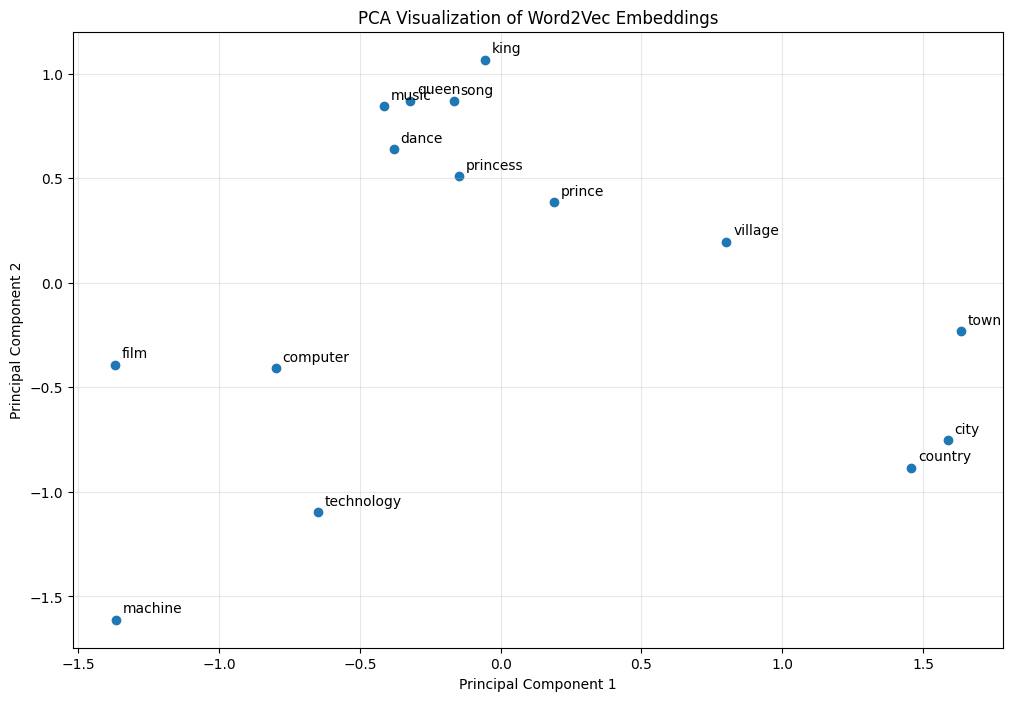

Explained variance: [0.2288 0.168 ]


In [ ]:
visual_words = [
    "king", "queen", "prince", "princess",
    "city", "town", "village", "country",
    "computer", "machine", "technology", "software",
    "music", "song", "dance", "film"
]

available_words = [
    word for word in visual_words
    if word in word2vec_model.wv
]

vectors = np.array([
    word2vec_model.wv[word]
    for word in available_words
])

pca = PCA(n_components=2)
pca_vectors = pca.fit_transform(vectors)

plt.figure(figsize=(12, 8))
plt.scatter(pca_vectors[:, 0], pca_vectors[:, 1])

for i, word in enumerate(available_words):
    plt.annotate(
        word,
        (pca_vectors[i, 0], pca_vectors[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("PCA Visualization of Word2Vec Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.3)
plt.show()

print(
    "Explained variance:",
    np.round(pca.explained_variance_ratio_, 4)
)

## 10. t-SNE Visualization

t-SNE is a nonlinear dimensionality-reduction method that is useful for examining local neighborhoods in high-dimensional embeddings.

The visualization is exploratory: positions in the two-dimensional plot should not be treated as exact measurements of semantic distance.

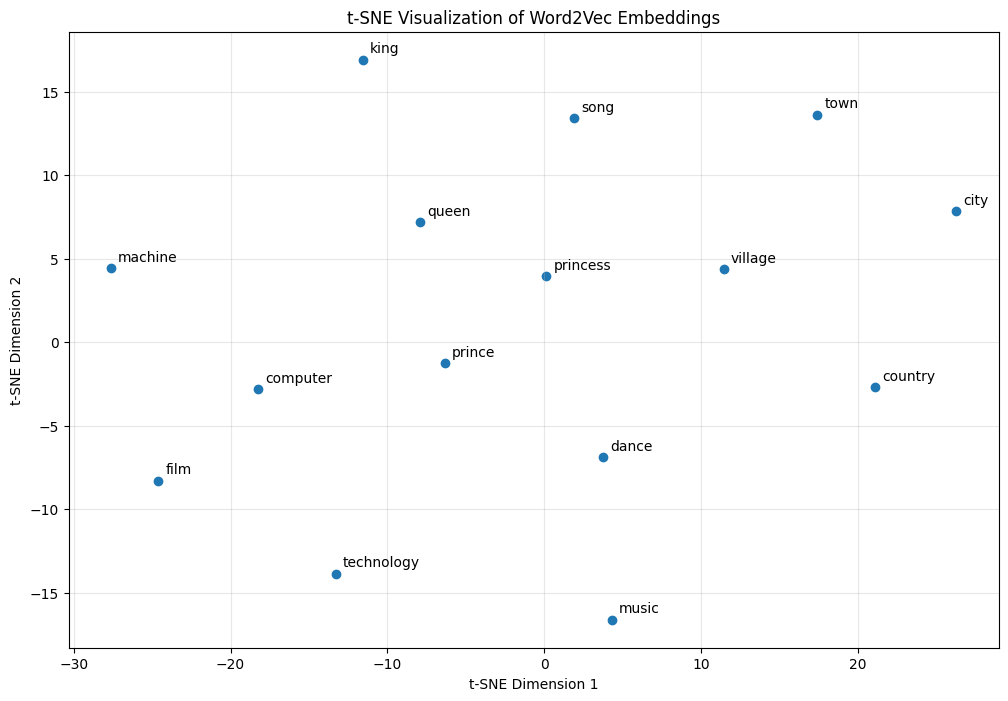

In [ ]:
perplexity_value = min(8, len(available_words) - 1)

tsne = TSNE(
    n_components=2,
    perplexity=perplexity_value,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

tsne_vectors = tsne.fit_transform(vectors)

plt.figure(figsize=(12, 8))
plt.scatter(tsne_vectors[:, 0], tsne_vectors[:, 1])

for i, word in enumerate(available_words):
    plt.annotate(
        word,
        (tsne_vectors[i, 0], tsne_vectors[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("t-SNE Visualization of Word2Vec Embeddings")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.grid(alpha=0.3)
plt.show()

## 11. Comparative Analysis

| Technique | Type | Semantic representation | OOV handling | Contextual understanding | Computational cost |
|---|---|---|---|---|---|
| One-Hot | Traditional | None | No | No | Low |
| Bag of Words | Traditional | Limited | No | No | Low–Moderate |
| TF-IDF | Traditional | Limited | No | No | Moderate |
| Word2Vec | Predictive/static | Strong | Limited | No | Moderate |
| FastText | Predictive/subword | Strong | Better | No | Moderate |
| Keras Embedding | Neural | Learned | Vocabulary-dependent | Usually no | Moderate |
| BERT | Transformer/contextual | Strong | Subword tokenization | Yes | High |

### Discussion

- **Traditional methods** are simple and useful as baselines but produce sparse representations.
- **Word2Vec** learns dense representations based on context.
- **FastText** improves rare/OOV word handling through character n-grams.
- **Keras Embedding** learns vectors as part of a neural-network training objective.
- **BERT** provides contextual representations, so the same word can have different embeddings in different sentences.